# Duplicate Assignment Detection — Group 7

Mini Project: Deep Learning for Engineers (Karnavati University, UIT)

This notebook converts the original Python script into eight runnable sections. Run the cells from top to bottom. A GPU runtime is recommended for training.

## STEP 1 | Install & import libraries + global configuration

In [10]:
# =============================================================================
# Mini Project - Deep Learning for Engineers (Karnavati University, UIT)
# Topic : Duplicate Assignment Detection - detect semantically similar
#         student submissions with a Siamese Sentence-BERT (bi-encoder).
# Syllabus mapping:
#   Unit II / CO2 -> Siamese network (twin encoders, shared weights, pair loss)
#   Unit IV / CO4 -> Transformer encoder, self-attention, text preprocessing
# Usage in Google Colab: paste each "# %% STEP n" block into its own cell
# (or upload this file and run it with  %run Group_x_1.py). Runtime -> GPU.
# =============================================================================
import importlib
import subprocess
import sys
import os
import re
import json
import random
import copy
import zipfile
import shutil
import textwrap
import html
from pathlib import Path


def _ensure(pip_name, import_name):
    """Install a package only if it cannot be imported."""
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        importlib.invalidate_caches()


for _pip, _imp in [
    ("torch", "torch"),
    ("transformers", "transformers"),
    ("sentence-transformers", "sentence_transformers"),
    ("datasets", "datasets"),
    ("scikit-learn", "sklearn"),
    ("PyMuPDF", "fitz"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("seaborn", "seaborn"),
]:
    _ensure(_pip, _imp)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sentence_transformers import util as st_util
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

try:
    import pymupdf as fitz  # newer PyMuPDF name
except ImportError:
    import fitz  # classic PyMuPDF name

# ----------------------------- Global configuration --------------------------
GROUP_NO = "7"                      # <-- CHANGE to your group number, e.g. "7"
SEED = 42
BASE_MODEL = "sentence-transformers/all-MiniLM-L6-v2"   # or "google-bert/bert-base-uncased"
LOSS_TYPE = "cosine"                # "cosine" (CosineSimilarityLoss) | "contrastive"
EPOCHS = 3
BATCH_SIZE = 16
LR = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
MAX_LEN = 128                       # max tokens per sentence/paragraph
CONTRASTIVE_MARGIN = 0.5
FLAG_THRESHOLD_PCT = 75.0           # demo verdict: >= 75 % -> FLAGGED
CHUNK_MAX_WORDS = 60                # demo: max words per compared text unit
MIN_UNIT_WORDS = 6                  # demo: ignore units shorter than this

DATA_DIR = Path("data")
SAVE_DIR = Path("saved_assignment_detector")


def set_seed(seed=SEED):
    """Make runs reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid")
print("Device :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (slower)")
print("Torch  :", torch.__version__)

Device : cuda | Tesla T4
Torch  : 2.14.1+cu130


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


## STEP 2 | Load public paraphrase dataset (GLUE / MRPC) and save 70/15/15 CSV splits

In [11]:
# MRPC = Microsoft Research Paraphrase Corpus: sentence pairs labelled
#   1 = semantically equivalent (paraphrase)  ->  "duplicate / plagiarised"
#   0 = not equivalent                         ->  "original"
def load_glue_mrpc():
    try:
        ds = load_dataset("nyu-mll/glue", "mrpc")
    except Exception:
        ds = load_dataset("glue", "mrpc")
    frames = [ds[s].to_pandas()[["sentence1", "sentence2", "label"]] for s in ds.keys()]
    return pd.concat(frames, ignore_index=True)


raw_df = load_glue_mrpc()
raw_df = raw_df.dropna(subset=["sentence1", "sentence2", "label"])
raw_df = raw_df[raw_df["label"].isin([0, 1])].copy()          # drop unlabeled rows if any
raw_df["sentence1"] = raw_df["sentence1"].astype(str).str.strip()
raw_df["sentence2"] = raw_df["sentence2"].astype(str).str.strip()
raw_df["label"] = raw_df["label"].astype(int)
raw_df = raw_df.drop_duplicates(subset=["sentence1", "sentence2"]).reset_index(drop=True)
raw_df.insert(0, "id", np.arange(len(raw_df)))
print("Total clean pairs (GLUE train+val+test merged):", len(raw_df))

# Stratified 70 % / 15 % / 15 % split (same class ratio in every split)
train_df, temp_df = train_test_split(
    raw_df, test_size=0.30, stratify=raw_df["label"], random_state=SEED, shuffle=True
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED, shuffle=True
)
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))

# Folder structure required by the guideline:
#   data/train/train.csv   data/validate/validate.csv   data/test/test.csv
for split_name, split_df in [("train", train_df), ("validate", val_df), ("test", test_df)]:
    (DATA_DIR / split_name).mkdir(parents=True, exist_ok=True)
    split_df.to_csv(DATA_DIR / split_name / f"{split_name}.csv", index=False, encoding="utf-8")

print(f"Train: {len(train_df)} ({len(train_df)/len(raw_df):.0%}) | "
      f"Validate: {len(val_df)} ({len(val_df)/len(raw_df):.0%}) | "
      f"Test: {len(test_df)} ({len(test_df)/len(raw_df):.0%})")
for p in sorted(DATA_DIR.rglob("*.csv")):
    print("saved ->", p, f"({p.stat().st_size/1024:.0f} KB)")

# Reload from disk so every later step uses exactly the saved files
train_df = pd.read_csv(DATA_DIR / "train" / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validate" / "validate.csv")
test_df = pd.read_csv(DATA_DIR / "test" / "test.csv")

Total clean pairs (GLUE train+val+test merged): 5801
Train: 4060 (70%) | Validate: 870 (15%) | Test: 871 (15%)
saved -> data/test/test.csv (212 KB)
saved -> data/train/train.csv (990 KB)
saved -> data/validate/validate.csv (211 KB)


## STEP 3 | Exploratory Data Analysis (EDA)

=== Dataset shapes (rows, columns) ===
Train    : (4060, 4)
Validate : (870, 4)
Test     : (871, 4)

Columns: ['id', 'sentence1', 'sentence2', 'label']
Missing values (train): 0

=== Sample student-submission pairs ===

--- label = 1 -> SIMILAR (paraphrase / duplicate) ---
Student A: Hedge funds came under renewed scrutiny recently when New York Attorney General Eliot Spitzer
unveiled a probe of illegal trading in mutual fund shares .
Student B: The industry came under renewed scrutiny recently with the launch by New York Attorney General
Eliot Spitzer of an investigation of illegal trading in mutual fund shares .

Student A: The picture changes a bit should Sen. Hillary Rodham Clinton be the Democratic presidential
candidate .
Student B: The picture changes slightly should New York Sen. Hillary Rodham Clinton end up as the Democratic
presidential candidate .

Student A: Mr. Bergonzi was the finance chief from 1995 until his departure in 1999 , and was intimately
involved in the allege

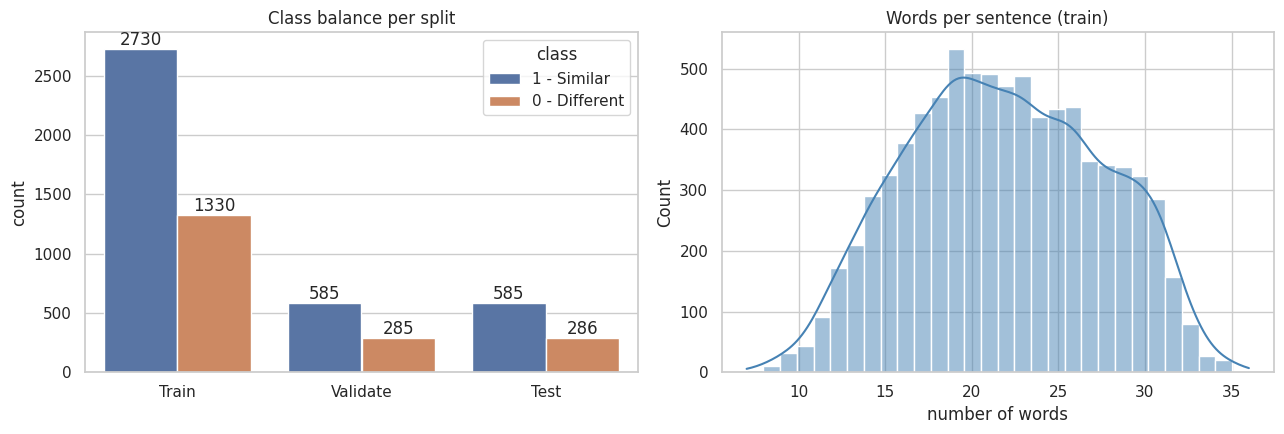

In [12]:
splits = {"Train": train_df, "Validate": val_df, "Test": test_df}

print("=== Dataset shapes (rows, columns) ===")
for name, d in splits.items():
    print(f"{name:9s}: {d.shape}")
print("\nColumns:", list(train_df.columns))
print("Missing values (train):", int(train_df.isna().sum().sum()))

print("\n=== Sample student-submission pairs ===")
label_text = {1: "SIMILAR (paraphrase / duplicate)", 0: "DIFFERENT (original)"}
for lab in (1, 0):
    print(f"\n--- label = {lab} -> {label_text[lab]} ---")
    for _, row in train_df[train_df["label"] == lab].sample(3, random_state=SEED).iterrows():
        print(textwrap.fill("Student A: " + row["sentence1"], 110))
        print(textwrap.fill("Student B: " + row["sentence2"], 110))
        print()

balance = pd.concat(
    [d.assign(split=n) for n, d in splits.items()], ignore_index=True
)
balance["class"] = balance["label"].map({0: "0 - Different", 1: "1 - Similar"})
print("=== Class balance (counts) ===")
print(pd.crosstab(balance["split"], balance["class"]))
print("\n=== Class balance (%) ===")
print((pd.crosstab(balance["split"], balance["class"], normalize="index") * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=balance, x="split", hue="class", order=["Train", "Validate", "Test"], ax=axes[0])
axes[0].set_title("Class balance per split")
axes[0].set_xlabel("")
for cont in axes[0].containers:
    axes[0].bar_label(cont)

len_df = pd.DataFrame({
    "words": pd.concat([train_df["sentence1"], train_df["sentence2"]]).str.split().str.len()
})
sns.histplot(len_df["words"], bins=30, kde=True, ax=axes[1], color="steelblue")
axes[1].set_title("Words per sentence (train)")
axes[1].set_xlabel("number of words")
plt.tight_layout()
plt.show()

## STEP 4 | Siamese Sentence-BERT model + fine-tuning (3 epochs, AdamW, lr=2e-5, bs=16, seed=42)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model: sentence-transformers/all-MiniLM-L6-v2 | params: 22.7 M | loss: cosine | steps: 762
Epoch 1/3 | train loss 0.1706 | val loss 0.1596
Epoch 2/3 | train loss 0.1418 | val loss 0.1553
Epoch 3/3 | train loss 0.1236 | val loss 0.1550
Restored best checkpoint: epoch 3 (val loss 0.1550)


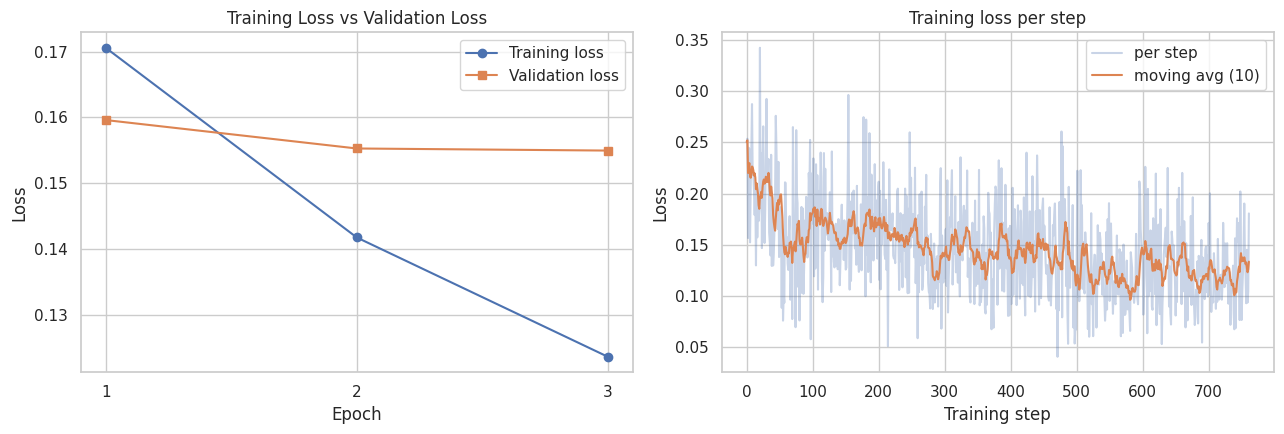

In [13]:
class SiameseSBERT(nn.Module):
    """
    Siamese bi-encoder.
    Both texts go through the SAME Transformer encoder (shared weights = the
    two 'twins'), are mean-pooled into fixed-size embeddings, and compared
    with cosine similarity.
    """

    def __init__(self, base_name, max_len=MAX_LEN):
        super().__init__()
        self.base_name = base_name
        self.max_len = max_len
        self.tokenizer = AutoTokenizer.from_pretrained(base_name)
        self.encoder = AutoModel.from_pretrained(base_name)   # self-attention layers

    def embed(self, texts):
        """texts: list[str] -> (batch, hidden) sentence embeddings."""
        dev = next(self.parameters()).device
        enc = self.tokenizer(
            list(texts), padding=True, truncation=True,
            max_length=self.max_len, return_tensors="pt",
        ).to(dev)
        token_emb = self.encoder(**enc).last_hidden_state              # (B, T, H)
        mask = enc["attention_mask"].unsqueeze(-1).float()             # (B, T, 1)
        return (token_emb * mask).sum(1) / mask.sum(1).clamp(min=1e-9)  # mean pooling

    def forward(self, texts_a, texts_b):
        emb_a = self.embed(texts_a)       # twin 1
        emb_b = self.embed(texts_b)       # twin 2 (same weights)
        return F.cosine_similarity(emb_a, emb_b, dim=1)


def cosine_similarity_loss(cos, y):
    """CosineSimilarityLoss: MSE between cosine score and target label (0/1)."""
    return F.mse_loss(cos, y)


def contrastive_loss(cos, y, margin=CONTRASTIVE_MARGIN):
    """ContrastiveLoss on cosine distance d = 1 - cos."""
    d = 1.0 - cos
    return 0.5 * (y * d.pow(2) + (1.0 - y) * F.relu(margin - d).pow(2)).mean()


loss_fn = cosine_similarity_loss if LOSS_TYPE == "cosine" else contrastive_loss


class PairDataset(Dataset):
    def __init__(self, df):
        self.s1 = df["sentence1"].tolist()
        self.s2 = df["sentence2"].tolist()
        self.y = df["label"].astype(int).tolist()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.s1[i], self.s2[i], self.y[i]


def collate(batch):
    s1, s2, y = zip(*batch)
    return list(s1), list(s2), torch.tensor(y, dtype=torch.float32)


set_seed(SEED)
g = torch.Generator()
g.manual_seed(SEED)
train_loader = DataLoader(PairDataset(train_df), batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate, generator=g)
val_loader = DataLoader(PairDataset(val_df), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)

model = SiameseSBERT(BASE_MODEL).to(device)
no_decay = ["bias", "LayerNorm.weight"]
param_groups = [
    {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
     "weight_decay": WEIGHT_DECAY},
    {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
     "weight_decay": 0.0},
]
optimizer = torch.optim.AdamW(param_groups, lr=LR)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
print(f"Model: {BASE_MODEL} | params: {sum(p.numel() for p in model.parameters())/1e6:.1f} M | "
      f"loss: {LOSS_TYPE} | steps: {total_steps}")

step_losses = []


def run_epoch(loader, train):
    model.train(train)
    total, n = 0.0, 0
    for s1, s2, y in loader:
        y = y.to(device)
        if train:
            optimizer.zero_grad()
        with torch.set_grad_enabled(train):
            cos = model(s1, s2)
            loss = loss_fn(cos, y)
        if train:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            step_losses.append(loss.item())
        total += loss.item() * len(y)
        n += len(y)
    return total / n


history = {"epoch": [], "train_loss": [], "val_loss": []}
best_val, best_state, best_epoch = float("inf"), None, 0
for epoch in range(1, EPOCHS + 1):
    tr = run_epoch(train_loader, train=True)
    va = run_epoch(val_loader, train=False)
    history["epoch"].append(epoch)
    history["train_loss"].append(tr)
    history["val_loss"].append(va)
    print(f"Epoch {epoch}/{EPOCHS} | train loss {tr:.4f} | val loss {va:.4f}")
    if va < best_val:
        best_val, best_epoch = va, epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)          # keep the best epoch (lowest validation loss)
model.eval()
print(f"Restored best checkpoint: epoch {best_epoch} (val loss {best_val:.4f})")

# --- Training loss vs Validation loss ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history["epoch"], history["train_loss"], "o-", label="Training loss")
axes[0].plot(history["epoch"], history["val_loss"], "s-", label="Validation loss")
axes[0].set_xticks(history["epoch"])
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training Loss vs Validation Loss")
axes[0].legend()
win = 10
smooth = pd.Series(step_losses).rolling(win, min_periods=1).mean()
axes[1].plot(step_losses, alpha=0.3, label="per step")
axes[1].plot(smooth, label=f"moving avg ({win})")
axes[1].set_xlabel("Training step")
axes[1].set_ylabel("Loss")
axes[1].set_title("Training loss per step")
axes[1].legend()
plt.tight_layout()
plt.show()

## STEP 5 | Evaluation on the test set (+ cosine-threshold tuning, confusion matrix)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Best cosine threshold (tuned on validation set): 0.590 (val weighted-F1 = 0.7787)

================ TEST SET RESULTS (fine-tuned Siamese SBERT) ================
Accuracy              : 0.7773  (77.73 %)
Precision (weighted)  : 0.7707  (77.07 %)
Recall (weighted)     : 0.7773  (77.73 %)
F1 (weighted)         : 0.7666  (76.66 %)
ROC-AUC               : 0.8302

Classification report:
               precision    recall  f1-score   support

0 - Different     0.7212    0.5245    0.6073       286
  1 - Similar     0.7949    0.9009    0.8446       585

     accuracy                         0.7773       871
    macro avg     0.7580    0.7127    0.7259       871
 weighted avg     0.7707    0.7773    0.7666       871

Comparison table (test set):
                                       Accuracy  Precision (weighted)  Recall (weighted)  F1 (weighted)  ROC-AUC
Pretrained, no fine-tuning (thr=0.73)    0.7072                0.6970             0.7072         0.7002   0.7187
Fine-tuned @ threshold 0.50 

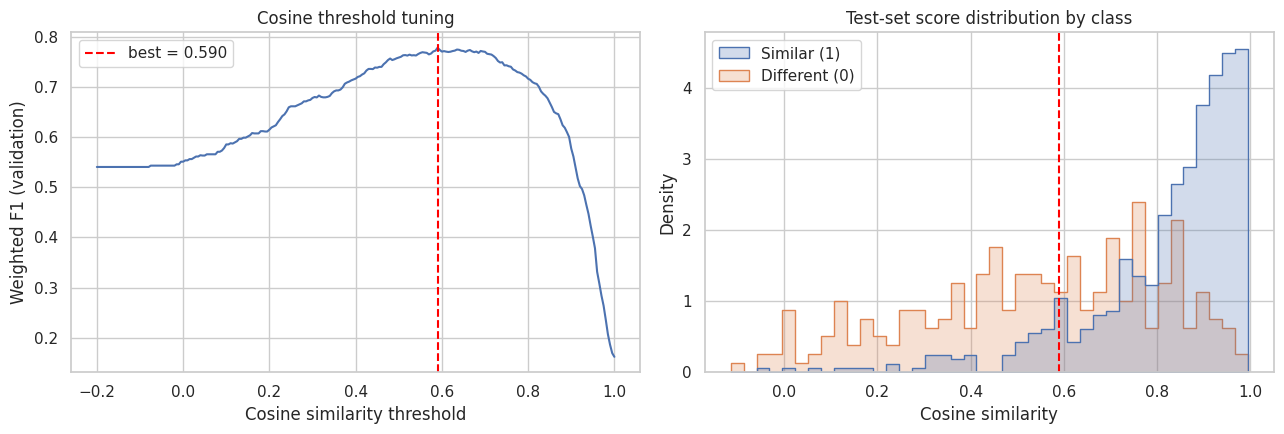

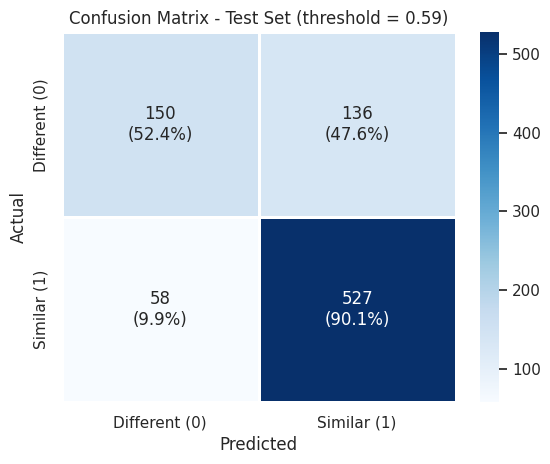

In [14]:
@torch.no_grad()
def predict_scores(m, df, bs=64):
    """Cosine similarity of every pair in df."""
    m.eval()
    out = []
    s1, s2 = df["sentence1"].tolist(), df["sentence2"].tolist()
    for i in range(0, len(df), bs):
        out.append(m(s1[i:i + bs], s2[i:i + bs]).float().cpu().numpy())
    return np.concatenate(out)


def tune_threshold(scores, labels, grid=None):
    """Pick the cosine threshold with the best weighted F1 (use VALIDATION data only)."""
    grid = np.arange(-0.2, 1.0001, 0.005) if grid is None else grid
    f1s = np.array([f1_score(labels, (scores >= t).astype(int), average="weighted", zero_division=0)
                    for t in grid])
    best = int(np.argmax(f1s))
    return float(grid[best]), float(f1s[best]), grid, f1s


def compute_metrics(labels, preds, scores):
    p, r, f, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    return {
        "Accuracy": accuracy_score(labels, preds),
        "Precision (weighted)": p,
        "Recall (weighted)": r,
        "F1 (weighted)": f,
        "ROC-AUC": roc_auc_score(labels, scores),
    }


y_val, y_test = val_df["label"].values, test_df["label"].values

# Baseline = same architecture WITHOUT fine-tuning (to show the benefit of training)
base_model = SiameseSBERT(BASE_MODEL).to(device)
base_val, base_test = predict_scores(base_model, val_df), predict_scores(base_model, test_df)
base_thr, _, _, _ = tune_threshold(base_val, y_val)
del base_model
if device.type == "cuda":
    torch.cuda.empty_cache()

# Fine-tuned model
val_scores, test_scores = predict_scores(model, val_df), predict_scores(model, test_df)
BEST_THRESHOLD, best_val_f1, grid, f1_curve = tune_threshold(val_scores, y_val)
test_pred = (test_scores >= BEST_THRESHOLD).astype(int)
print(f"Best cosine threshold (tuned on validation set): {BEST_THRESHOLD:.3f} "
      f"(val weighted-F1 = {best_val_f1:.4f})")

m_ft = compute_metrics(y_test, test_pred, test_scores)
m_ft_05 = compute_metrics(y_test, (test_scores >= 0.5).astype(int), test_scores)
m_base = compute_metrics(y_test, (base_test >= base_thr).astype(int), base_test)

print("\n================ TEST SET RESULTS (fine-tuned Siamese SBERT) ================")
for k, v in m_ft.items():
    print(f"{k:22s}: {v:.4f}" + ("  (%.2f %%)" % (v * 100) if k != "ROC-AUC" else ""))
print("\nClassification report:")
print(classification_report(y_test, test_pred, target_names=["0 - Different", "1 - Similar"], digits=4))

print("Comparison table (test set):")
comparison = pd.DataFrame({
    f"Pretrained, no fine-tuning (thr={base_thr:.2f})": m_base,
    "Fine-tuned @ threshold 0.50": m_ft_05,
    f"Fine-tuned @ tuned thr={BEST_THRESHOLD:.2f}": m_ft,
}).T.round(4)
print(comparison.to_string())

# --- Threshold curve + score distribution ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(grid, f1_curve)
axes[0].axvline(BEST_THRESHOLD, color="red", ls="--", label=f"best = {BEST_THRESHOLD:.3f}")
axes[0].set_xlabel("Cosine similarity threshold")
axes[0].set_ylabel("Weighted F1 (validation)")
axes[0].set_title("Cosine threshold tuning")
axes[0].legend()
sns.histplot(x=test_scores, hue=np.where(y_test == 1, "Similar (1)", "Different (0)"),
             bins=40, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].axvline(BEST_THRESHOLD, color="red", ls="--")
axes[1].set_xlabel("Cosine similarity")
axes[1].set_title("Test-set score distribution by class")
plt.tight_layout()
plt.show()

# --- Confusion matrix heatmap ---
cm = confusion_matrix(y_test, test_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
annot = np.array([[f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
plt.figure(figsize=(5.8, 4.8))
sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=True, linewidths=1, linecolor="white",
            xticklabels=["Different (0)", "Similar (1)"], yticklabels=["Different (0)", "Similar (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - Test Set (threshold = {BEST_THRESHOLD:.2f})")
plt.tight_layout()
plt.show()

## STEP 6 | Live demo: compare two student assignments (PDF / TXT)

In [15]:
def _clean_text(t):
    t = re.sub(r"-\s*\n\s*", "", t)          # join words hyphenated across lines
    return re.sub(r"\s+", " ", t).strip()


def _chunk_sentences(text, max_words=CHUNK_MAX_WORDS):
    """Greedily group sentences into units of at most max_words words."""
    sentences = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]
    units, cur, cur_n = [], [], 0
    for s in sentences:
        n = len(s.split())
        if cur and cur_n + n > max_words:
            units.append(" ".join(cur))
            cur, cur_n = [], 0
        cur.append(s)
        cur_n += n
    if cur:
        units.append(" ".join(cur))
    return units


def extract_units(path):
    """Read a .pdf/.txt file and return a list of paragraph/sentence-group text units."""
    path = str(path)
    ext = Path(path).suffix.lower()
    if ext == ".pdf":
        doc = fitz.open(path)
        raw = []
        for page in doc:
            for blk in page.get_text("blocks", sort=True):
                if blk[6] == 0:                         # 0 = text block
                    raw.append(_clean_text(blk[4]))
        doc.close()
    elif ext in (".txt", ".md"):
        txt = Path(path).read_text(encoding="utf-8", errors="ignore")
        raw = [_clean_text(p) for p in re.split(r"\n\s*\n", txt)]
        if len(raw) < 3:                                # no blank-line paragraphs
            raw = [_clean_text(p) for p in txt.splitlines()]
    else:
        raise ValueError(f"Unsupported file type '{ext}'. Use .pdf or .txt")

    raw = [p for p in raw if p]
    if not raw:
        raise ValueError(f"No extractable text in {Path(path).name} "
                         "(scanned PDF? PyMuPDF does not do OCR).")

    lengths = [len(p.split()) for p in raw]
    if ext == ".pdf" and (len(raw) < 2 or float(np.median(lengths)) < 8):
        # PDF blocks are single lines -> rebuild text and chunk by sentences
        raw = [" ".join(raw)]

    units = []
    for p in raw:
        if len(p.split()) > CHUNK_MAX_WORDS:
            units.extend(_chunk_sentences(p))
        else:
            units.append(p)
    units = [u for u in units if len(u.split()) >= MIN_UNIT_WORDS]
    if not units:
        raise ValueError(f"Text in {Path(path).name} is too short to analyse.")
    return units


@torch.no_grad()
def embed_texts(texts, bs=32):
    model.eval()
    chunks = [model.embed(texts[i:i + bs]).cpu() for i in range(0, len(texts), bs)]
    return F.normalize(torch.cat(chunks), dim=1)


def compare_documents(units_a, units_b):
    """Return overall similarity (0-100 %) and the top-3 distinct matching unit pairs."""
    emb_a, emb_b = embed_texts(units_a), embed_texts(units_b)
    sim = st_util.cos_sim(emb_a, emb_b).numpy()                 # (nA, nB) matrix

    # Overall score = symmetric mean of "best match" similarity of each unit
    score = (sim.max(axis=1).mean() + sim.max(axis=0).mean()) / 2.0
    overall_pct = float(np.clip(score, 0.0, 1.0) * 100.0)

    thr = globals().get("BEST_THRESHOLD", 0.5)
    matched_a = float((sim.max(axis=1) >= thr).mean() * 100.0)
    matched_b = float((sim.max(axis=0) >= thr).mean() * 100.0)

    # Greedy top-3 pairs, each paragraph used at most once
    order = np.dstack(np.unravel_index(np.argsort(-sim, axis=None), sim.shape))[0]
    top, used_a, used_b = [], set(), set()
    for i, j in order:
        if i in used_a or j in used_b:
            continue
        top.append((int(i), int(j), float(sim[i, j])))
        used_a.add(i)
        used_b.add(j)
        if len(top) == 3:
            break
    return overall_pct, top, matched_a, matched_b


def _highlight_shared(text, other):
    """HTML-escape text and <mark> the words that also appear in the other paragraph."""
    other_words = set(re.findall(r"[A-Za-z0-9']+", other.lower()))
    out = []
    for part in re.split(r"([A-Za-z0-9']+)", text):
        if part and re.fullmatch(r"[A-Za-z0-9']+", part) and len(part) > 3 and part.lower() in other_words:
            out.append(f"<mark style='background:#ffd54f;color:#000;padding:0 2px'>{html.escape(part)}</mark>")
        else:
            out.append(html.escape(part))
    return "".join(out)


def live_demo(path_a=None, path_b=None):
    """
    Viva demo. In Colab call live_demo() and select TWO files (.pdf / .txt)
    in the upload dialog. Outside Colab: live_demo('a.pdf', 'b.pdf').
    """
    if path_a is None or path_b is None:
        try:
            from google.colab import files
        except ImportError:
            print("Not running in Colab -> call live_demo('studentA.pdf', 'studentB.pdf')")
            return None
        print("Select exactly TWO assignment files (Student A first, Student B second) ...")
        uploaded = files.upload()
        names = list(uploaded.keys())
        if len(names) != 2:
            print(f"Expected 2 files but received {len(names)}. Run live_demo() again.")
            return None
        for n in names:
            Path(n).write_bytes(uploaded[n])
        path_a, path_b = names

    units_a, units_b = extract_units(path_a), extract_units(path_b)
    overall_pct, top, matched_a, matched_b = compare_documents(units_a, units_b)
    flagged = overall_pct >= FLAG_THRESHOLD_PCT
    verdict = "FLAGGED: Semantically Similar / Plagiarized" if flagged else "ORIGINAL SUBMISSION"

    print("=" * 78)
    print(f"Student A : {Path(path_a).name}  ({len(units_a)} text units)")
    print(f"Student B : {Path(path_b).name}  ({len(units_b)} text units)")
    print(f"(a) Overall Semantic Similarity : {overall_pct:.1f} %")
    print(f"(b) Final Verdict               : {verdict}   [flag rule: >= {FLAG_THRESHOLD_PCT:.0f} %]")
    print(f"    Units with a close match    : A {matched_a:.0f} % | B {matched_b:.0f} %")
    print("=" * 78)

    try:
        from IPython.display import display, HTML
        colour = "#c62828" if flagged else "#2e7d32"
        parts = [
            f"<div style='font-family:sans-serif;padding:12px;border:3px solid {colour};"
            f"border-radius:8px;background:#fafafa;color:#111;margin-bottom:10px'>"
            f"<div style='font-size:15px'>(a) Overall Semantic Similarity</div>"
            f"<div style='font-size:34px;font-weight:bold;color:{colour}'>{overall_pct:.1f} %</div>"
            f"<div style='font-size:18px;font-weight:bold;color:{colour}'>(b) {html.escape(verdict)}</div></div>",
            "<div style='font-family:sans-serif;font-size:16px;font-weight:bold;margin:8px 0'>"
            "(c) Top 3 most similar matching paragraphs</div>",
        ]
        for rank, (i, j, s) in enumerate(top, 1):
            parts.append(
                "<div style='font-family:sans-serif;border:1px solid #bbb;border-radius:6px;"
                "padding:10px;margin:8px 0;background:#fffdf5;color:#111'>"
                f"<b>Match #{rank} - similarity {s * 100:.1f} %</b>"
                f"<p><b>Student A (unit {i + 1}):</b> {_highlight_shared(units_a[i], units_b[j])}</p>"
                f"<p><b>Student B (unit {j + 1}):</b> {_highlight_shared(units_b[j], units_a[i])}</p></div>"
            )
        display(HTML("".join(parts)))
    except Exception:
        print("\n(c) Top 3 most similar matching paragraphs")
        for rank, (i, j, s) in enumerate(top, 1):
            print(f"\n--- Match #{rank}: {s * 100:.1f} % ---")
            print(textwrap.fill("A: " + units_a[i], 100))
            print(textwrap.fill("B: " + units_b[j], 100))

    return {"similarity_pct": overall_pct, "verdict": verdict, "top_matches": top}


print("live_demo() is ready. Run STEP 8 (or call live_demo()) to start the demo.")

live_demo() is ready. Run STEP 8 (or call live_demo()) to start the demo.


## STEP 7 | Save the trained model + build Group_x_code.zip

In [16]:
# 7a) Save model to saved_assignment_detector/
SAVE_DIR.mkdir(parents=True, exist_ok=True)
model.encoder.save_pretrained(SAVE_DIR)
model.tokenizer.save_pretrained(SAVE_DIR)
with open(SAVE_DIR / "siamese_config.json", "w") as fh:
    json.dump({
        "base_model": BASE_MODEL, "max_len": MAX_LEN, "loss": LOSS_TYPE,
        "best_threshold": BEST_THRESHOLD, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
        "lr": LR, "seed": SEED, "flag_threshold_pct": FLAG_THRESHOLD_PCT,
    }, fh, indent=2)
print("Model saved to:", SAVE_DIR.resolve())


def load_siamese(path=SAVE_DIR):
    """Reload the saved detector (what you would use for deployment)."""
    cfg = json.load(open(Path(path) / "siamese_config.json"))
    m = SiameseSBERT(str(path), cfg["max_len"]).to(device)
    m.eval()
    return m, cfg


# Sanity check: reloaded model must give the same score as the in-memory model
reloaded, _cfg = load_siamese()
_pair = test_df.iloc[:1]
_diff = abs(float(predict_scores(reloaded, _pair)[0]) - float(predict_scores(model, _pair)[0]))
print(f"Reload check -> score difference = {_diff:.2e}", "(OK)" if _diff < 1e-4 else "(CHECK!)")
del reloaded


# 7b) Build Group_<x>_code.zip :  Group_<x>_1.py  +  data/{train,validate,test}/
def get_script_source():
    """Return the source code of this project."""
    try:
        p = Path(__file__)
        if p.suffix == ".py" and p.exists():
            return p.read_text(encoding="utf-8")
    except NameError:
        pass

    try:
        history = get_ipython().user_ns.get("In", [])
    except NameError:
        history = []

    # Try to filter by step markers
    cells = {}
    for c in history:
        m = re.match(r"\s*# %% STEP (\d+)", c)
        if m:
            cells[int(m.group(1))] = c

    if cells:
        return "\n\n\n".join(cells[k].rstrip() for k in sorted(cells)) + "\n"

    # Fallback: Concatenate all execution history except this cell
    non_empty_code = [c.rstrip() for c in history if c.strip() and "get_script_source" not in c]
    if non_empty_code:
        return "\n\n\n".join(non_empty_code) + "\n"

    local = Path(f"Group_{GROUP_NO}_1.py")
    if local.exists():
        return local.read_text(encoding="utf-8")
    return None


script_name = f"Group_{GROUP_NO}_1.py"
zip_name = f"Group_{GROUP_NO}_code.zip"
source = get_script_source()
if source is None:
    raise RuntimeError(
        f"Could not find the script source. Upload your code as {script_name} "
        "to the Colab working directory (left sidebar -> Files) and run this step again."
    )
Path(script_name).write_text(source, encoding="utf-8")

if Path(zip_name).exists():
    Path(zip_name).unlink()
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(script_name, arcname=script_name)
    for f in sorted(DATA_DIR.rglob("*")):
        if f.is_file():
            zf.write(f, arcname=f.as_posix())

print(f"\nCreated {zip_name} ({Path(zip_name).stat().st_size/1024:.0f} KB). Contents:")
with zipfile.ZipFile(zip_name) as zf:
    for info in zf.infolist():
        print("  ", info.filename)

# Optional: also zip the trained model separately
shutil.make_archive("saved_assignment_detector", "zip", ".", str(SAVE_DIR))

try:
    from google.colab import files
    files.download(zip_name)
    files.download("saved_assignment_detector.zip")
except Exception:
    print("(Not in Colab - download the zip files from the working directory.)")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/saved_assignment_detector


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Reload check -> score difference = 0.00e+00 (OK)

Created Group_7_code.zip (487 KB). Contents:
   Group_7_1.py
   data/test/test.csv
   data/train/train.csv
   data/validate/validate.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## STEP 8 | RUN THE LIVE DEMO (viva): upload two assignment PDFs / TXT files

In [17]:
result = live_demo()

Select exactly TWO assignment files (Student A first, Student B second) ...


Saving Practical 4 CNN.pdf to Practical 4 CNN.pdf
Saving Practical 3 CNN.pdf to Practical 3 CNN.pdf
Student A : Practical 4 CNN.pdf  (1 text units)
Student B : Practical 3 CNN.pdf  (1 text units)
(a) Overall Semantic Similarity : 32.4 %
(b) Final Verdict               : ORIGINAL SUBMISSION   [flag rule: >= 75 %]
    Units with a close match    : A 0 % | B 0 %
